# iamp — Análise exploratória (EDA)

O que este notebook mostra:
1. **Catálogo de aparelhos** (Inmetro/PBE): quantos modelos há por categoria e quanto cada categoria consome tipicamente.
2. **Tarifas** (ANEEL, B1 residencial convencional, TUSD + TE): variação entre estados.
3. **Residências do ML**: seed por regras × sintéticas do CTGAN (validação do gerador).
4. **Perfis do K-Means**: como as casas se separam em Consciente / Moderado / Ineficiente.

Os gráficos são salvos em `docs/graficos/` para o deck e o documento de ética.
Cada gráfico vem com a tabela dos números logo abaixo.

> Para rodar: com o `.venv` ativo, `pip install -r requirements-ml.txt` e abra este notebook
> (ou `jupyter nbconvert --to notebook --execute --inplace notebooks/eda.ipynb`).

In [1]:
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

RAIZ = Path.cwd().resolve()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
import calculadora_residencial as calc
import config
import tarifas_aneel

GRAFICOS = RAIZ / "docs" / "graficos"
GRAFICOS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 120)

# Paleta (validada para daltonismo; ver docs/graficos/README.md)
SUPERFICIE, TEXTO, TEXTO_2, GRADE = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
AZUL, LARANJA, AQUA, AMARELO, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
PERFIL_COR = {"Consciente": "#86b6ef", "Moderado": "#2a78d6", "Ineficiente": "#104281"}  # ordinal, um so tom
NOMES = {"refrigerador": "Geladeira", "televisor": "TV", "ar_condicionado": "Ar-condicionado",
         "ventilador_de_mesa": "Ventilador de mesa", "ventilador_de_teto": "Ventilador de teto",
         "chuveiro": "Chuveiro", "lampada_led": "Lâmpada LED", "lampada_fluorescente": "Lâmpada fluorescente",
         "lampada_vapor_sodio": "Lâmpada vapor de sódio", "microondas": "Micro-ondas",
         "maquina_de_lavar": "Máquina de lavar", "bomba": "Bomba d'água"}

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 30, "text.color": TEXTO, "axes.labelcolor": TEXTO_2,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "axes.edgecolor": GRADE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "figure.dpi": 110,
})
brl = lambda v, casas=2: f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")
pct = FuncFormatter(lambda v, _: f"{v:.0%}")

def subtitulo(ax, texto):
    ax.text(0, 1.015, texto, transform=ax.transAxes, color=TEXTO_2, fontsize=10, va="bottom")

def fonte(fig, texto):
    fig.text(0.01, -0.01, "Fonte: " + texto, color=TEXTO_2, fontsize=8.5, ha="left", va="top")

def salvar(fig, nome):
    fig.savefig(GRAFICOS / nome, dpi=200, bbox_inches="tight")
    plt.show()

## 1. Catálogo de aparelhos (Inmetro)

O catálogo junta os CSVs limpos (`datasets/processed/`) em uma tabela só, a mesma que vai para o banco.

24.155 aparelhos em 12 categorias
origem_dado
informado                          92.7 %
derivado ou estimado na limpeza     7.3 %
Name: proportion, dtype: object


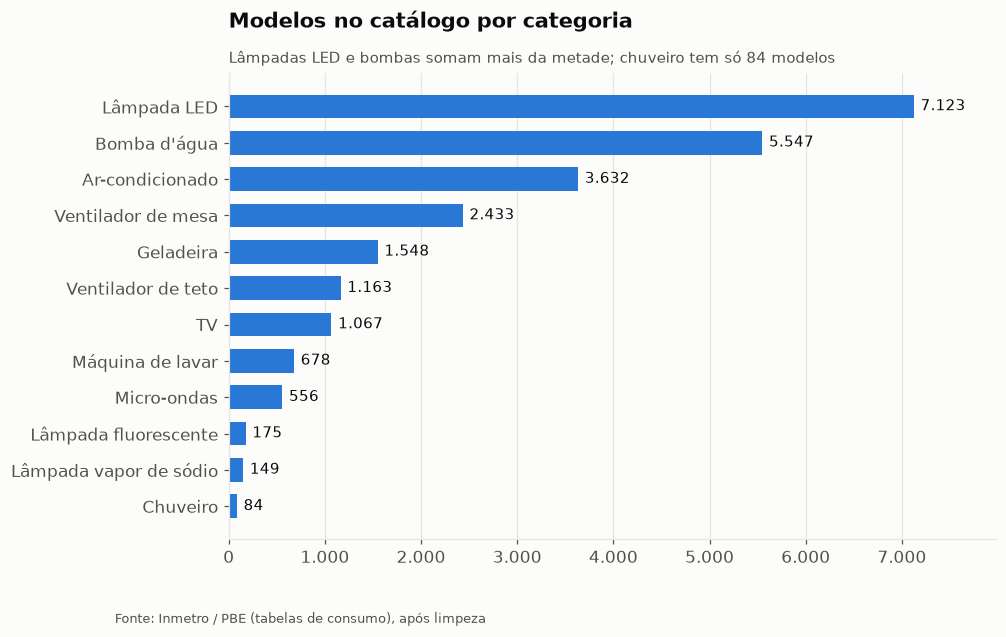

,modelos
nome,
Lâmpada LED,7123
Bomba d'água,5547
Ar-condicionado,3632
Ventilador de mesa,2433
Geladeira,1548
Ventilador de teto,1163
TV,1067
Máquina de lavar,678
Micro-ondas,556


In [2]:
cat = calc.carregar_catalogo()
cat["nome"] = cat["categoria"].map(NOMES)
por_cat = cat["nome"].value_counts().sort_values()
print(f"{len(cat):,} aparelhos em {cat['categoria'].nunique()} categorias".replace(",", "."))
print((cat["origem_dado"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(por_cat.index, por_cat.values, color=AZUL, height=0.65)
ax.grid(axis="y", visible=False)
for y, v in enumerate(por_cat.values):
    ax.text(v + por_cat.max() * 0.01, y, brl(v, 0), va="center", color=TEXTO, fontsize=9.5)
ax.set_xlim(0, por_cat.max() * 1.12)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: brl(v, 0)))
ax.set_title("Modelos no catálogo por categoria")
subtitulo(ax, "Lâmpadas LED e bombas somam mais da metade; chuveiro tem só 84 modelos")
fonte(fig, "Inmetro / PBE (tabelas de consumo), após limpeza")
salvar(fig, "01_catalogo_por_categoria.png")
por_cat.sort_values(ascending=False).to_frame("modelos")

### Consumo típico de cada categoria

Consumo mensal de um modelo **mediano** de cada categoria, calculado com as mesmas regras do app
(`consumo_mensal_kwh`). Onde o Inmetro não informa o kWh/mês, entram as premissas de uso do grupo
(ex.: lâmpada 5 h/dia, micro-ondas 20 min/dia); o chuveiro usa 15 min/dia, como no exemplo de referência.
**São estimativas** — o uso real muda tudo.

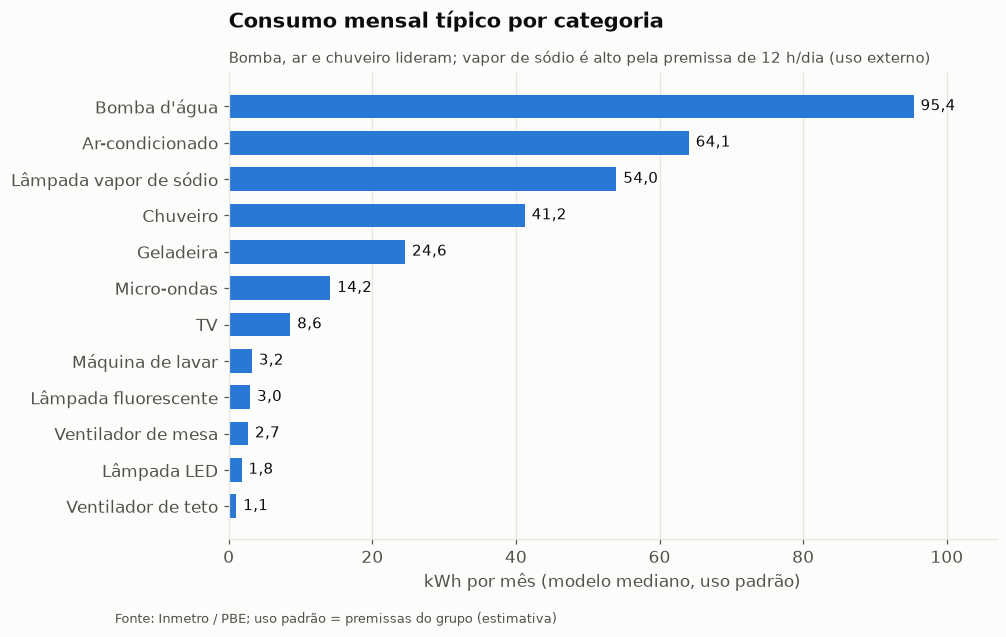

,kWh/mês
nome,
Bomba d'água,95.40
Ar-condicionado,64.08
Lâmpada vapor de sódio,54.00
Chuveiro,41.25
Geladeira,24.58
Micro-ondas,14.16
TV,8.58
Máquina de lavar,3.24
Lâmpada fluorescente,3.00


In [3]:
def consumo_padrao(linha):
    horas = 0.25 if linha["categoria"] == "chuveiro" else None
    try:
        return calc.consumo_mensal_kwh(linha, horas_dia=horas)["kwh_mes"]
    except ValueError:
        return np.nan

cat["kwh_padrao"] = [consumo_padrao(l) for l in cat.to_dict("records")]
tipico = cat.groupby("nome")["kwh_padrao"].median().dropna().sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(tipico.index, tipico.values, color=AZUL, height=0.65)
ax.grid(axis="y", visible=False)
for y, v in enumerate(tipico.values):
    ax.text(v + tipico.max() * 0.01, y, brl(v, 1), va="center", color=TEXTO, fontsize=9.5)
ax.set_xlim(0, tipico.max() * 1.12)
ax.set_xlabel("kWh por mês (modelo mediano, uso padrão)")
ax.set_title("Consumo mensal típico por categoria")
subtitulo(ax, "Bomba, ar e chuveiro lideram; vapor de sódio é alto pela premissa de 12 h/dia (uso externo)")
fonte(fig, "Inmetro / PBE; uso padrão = premissas do grupo (estimativa)")
salvar(fig, "02_consumo_tipico_categoria.png")
tipico.sort_values(ascending=False).round(2).to_frame("kWh/mês")

## 2. Tarifas por estado (ANEEL)

Tarifa B1 residencial convencional **vigente hoje** (TUSD + TE, sem impostos nem bandeira).
Quando um estado tem várias distribuidoras, o gráfico mostra a faixa (mín.–máx.) e a mediana.

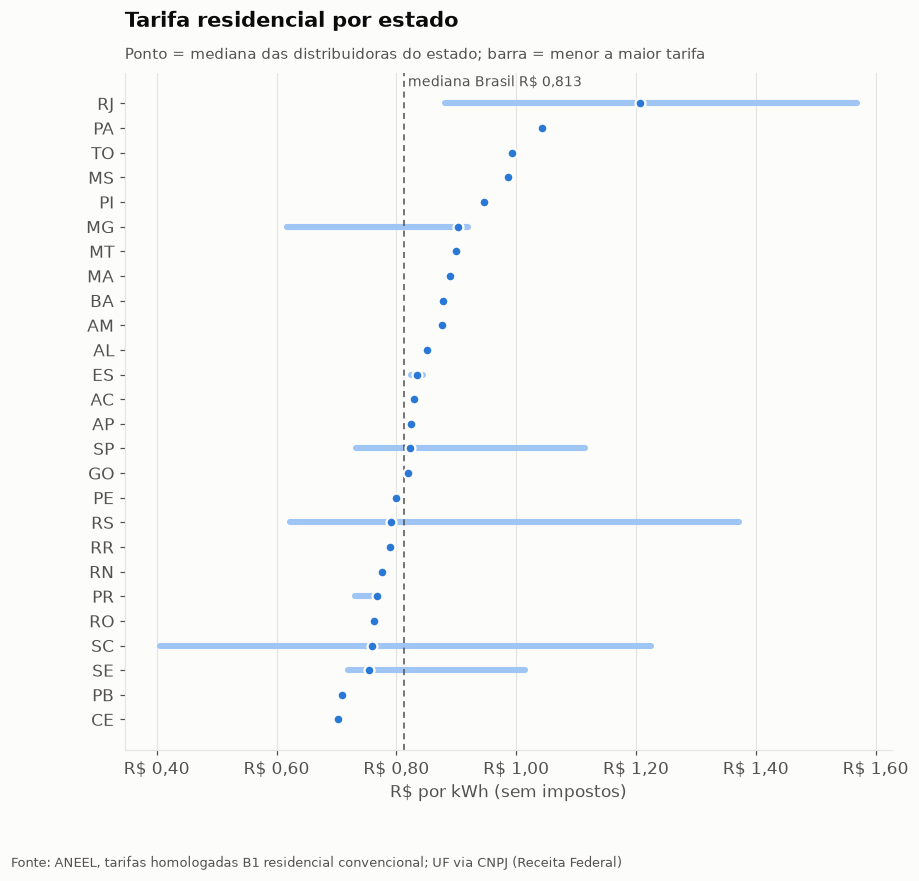

99 distribuidoras | menor R$ 0,405 | maior R$ 1,569


,min,median,max,count
uf,,,,
RJ,0.881,1.206,1.569,5
PA,1.043,1.043,1.043,1
TO,0.993,0.993,0.993,1
MS,0.987,0.987,0.987,1
PI,0.947,0.947,0.947,1
MG,0.618,0.903,0.919,3
MT,0.899,0.899,0.899,1
MA,0.889,0.889,0.889,1
BA,0.878,0.878,0.878,1


In [4]:
t = tarifas_aneel.ler_tarifas_residenciais()
t = t[t["vigencia_inicio"].fillna("") <= date.today().isoformat()].sort_values("vigencia_inicio")
t = t.drop_duplicates("nome", keep="last")
uf = pd.read_csv(config.DISTRIBUIDORAS_CSV, encoding="utf-8-sig")[["SigAgente", "uf"]]
t = t.merge(uf, left_on="nome", right_on="SigAgente")
por_uf = t.groupby("uf")["tarifa_kwh"].agg(["min", "median", "max", "count"]).sort_values("median")
mediana_br = t["tarifa_kwh"].median()

fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(por_uf))
ax.hlines(y, por_uf["min"], por_uf["max"], color="#9ec5f4", linewidth=4, capstyle="round")
ax.scatter(por_uf["median"], y, color=AZUL, s=42, zorder=3, edgecolor=SUPERFICIE, linewidth=1.5)
ax.axvline(mediana_br, color=TEXTO_2, linewidth=1, linestyle=(0, (4, 3)))
ax.text(mediana_br, len(por_uf) - 0.3, f" mediana Brasil R$ {brl(mediana_br, 3)}", color=TEXTO_2, fontsize=9)
ax.set_yticks(y, por_uf.index)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"R$ {brl(v)}"))
ax.set_xlabel("R$ por kWh (sem impostos)")
ax.set_title("Tarifa residencial por estado")
subtitulo(ax, "Ponto = mediana das distribuidoras do estado; barra = menor a maior tarifa")
fonte(fig, "ANEEL, tarifas homologadas B1 residencial convencional; UF via CNPJ (Receita Federal)")
salvar(fig, "03_tarifa_por_uf.png")
print(f"{len(t)} distribuidoras | menor R$ {brl(t['tarifa_kwh'].min(), 3)} | maior R$ {brl(t['tarifa_kwh'].max(), 3)}")
por_uf.sort_values("median", ascending=False).round(3)

## 3. Residências: seed por regras × sintéticas (CTGAN)

A seed (3.000 casas) é gerada por regras com aparelhos e tarifas reais; o CTGAN aprende a seed e gera
5.000 casas sintéticas. Aqui verificamos **o quanto o gerador preservou** da seed.
Lembrete: as duas bases são **sintéticas** e as regras da seed são premissas do grupo.

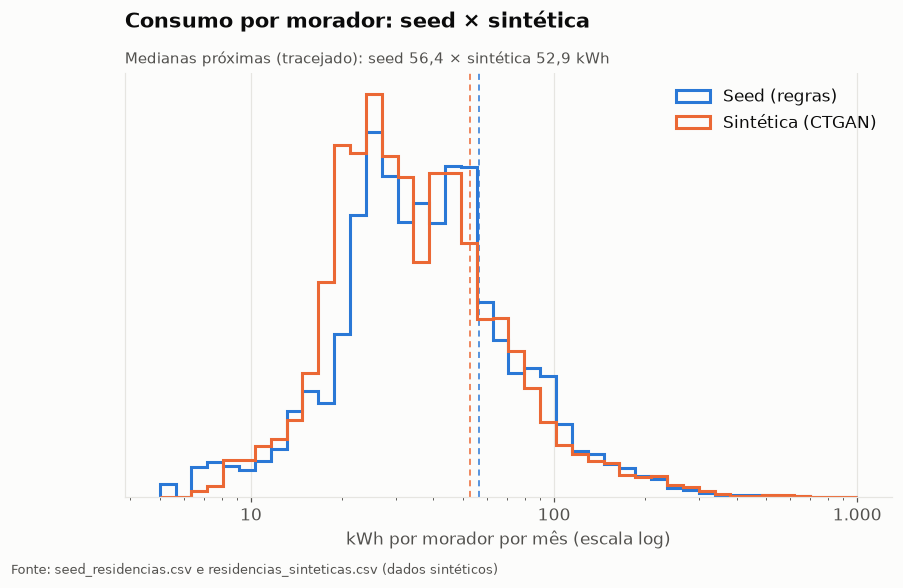

,seed,sintética
0.10,25.4,22.8
0.25,37.1,32.5
0.50,56.4,52.9
0.75,98.6,92.2
0.90,174.7,184.9
0.99,495.1,479.7


In [5]:
seed = pd.read_csv(config.DADOS / "seed_residencias.csv", encoding="utf-8-sig")
sint = pd.read_csv(config.DADOS / "residencias_sinteticas.csv", encoding="utf-8-sig")

bins = np.logspace(np.log10(5), np.log10(1000), 45)
fig, ax = plt.subplots(figsize=(9, 5))
for df, nome, cor in [(seed, "Seed (regras)", AZUL), (sint, "Sintética (CTGAN)", LARANJA)]:
    ax.hist(df["kwh_por_morador"], bins=bins, density=True, histtype="step", linewidth=2, color=cor, label=nome)
    med = df["kwh_por_morador"].median()
    ax.axvline(med, color=cor, linewidth=1, linestyle=(0, (4, 3)))
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: brl(v, 0)))
ax.set_yticks([])
ax.grid(axis="y", visible=False)
ax.set_xlabel("kWh por morador por mês (escala log)")
ax.legend(loc="upper right")
ax.set_title("Consumo por morador: seed × sintética")
subtitulo(ax, f"Medianas próximas (tracejado): seed {brl(seed['kwh_por_morador'].median(), 1)} × "
              f"sintética {brl(sint['kwh_por_morador'].median(), 1)} kWh")
fonte(fig, "seed_residencias.csv e residencias_sinteticas.csv (dados sintéticos)")
salvar(fig, "04_kwh_morador_seed_vs_sintetica.png")
q = [0.1, 0.25, 0.5, 0.75, 0.9, 0.99]
pd.DataFrame({"seed": seed["kwh_por_morador"].quantile(q), "sintética": sint["kwh_por_morador"].quantile(q)}).round(1)

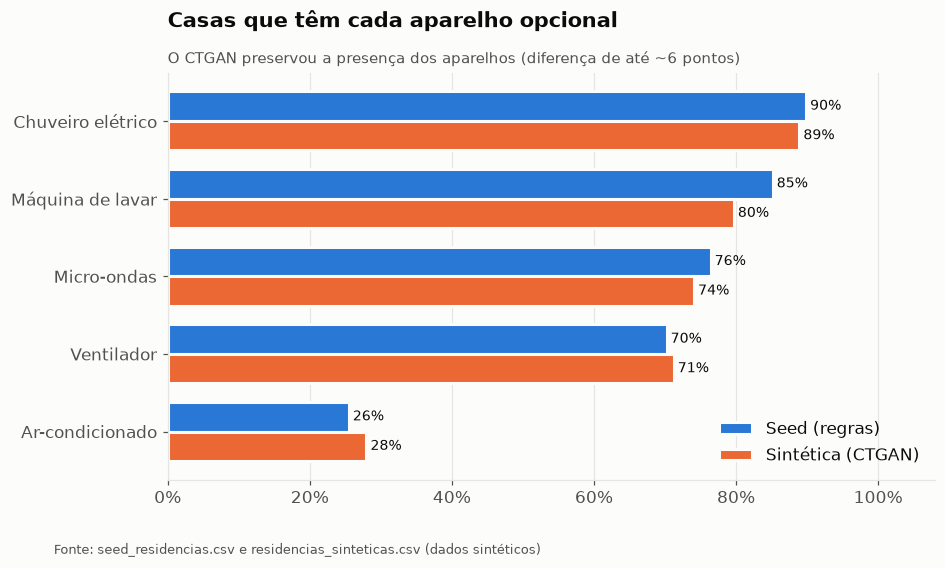

,seed,sintética
Ar-condicionado,25.5,28.0
Ventilador,70.2,71.2
Micro-ondas,76.4,74.1
Máquina de lavar,85.2,79.7
Chuveiro elétrico,89.9,88.9


In [6]:
def barras_lado_a_lado(ax, rotulos, a, b, fmt):
    y = np.arange(len(rotulos))
    h = 0.38
    ax.barh(y + h / 2, a, height=h, color=AZUL, label="Seed (regras)", edgecolor=SUPERFICIE, linewidth=2)
    ax.barh(y - h / 2, b, height=h, color=LARANJA, label="Sintética (CTGAN)", edgecolor=SUPERFICIE, linewidth=2)
    for yy, va, vb in zip(y, a, b):
        ax.text(va, yy + h / 2, " " + fmt(va), va="center", fontsize=9, color=TEXTO)
        ax.text(vb, yy - h / 2, " " + fmt(vb), va="center", fontsize=9, color=TEXTO)
    ax.set_yticks(y, rotulos)
    ax.grid(axis="y", visible=False)

tem = {"tem_chuveiro": "Chuveiro elétrico", "tem_maquina": "Máquina de lavar", "tem_microondas": "Micro-ondas",
       "tem_ventilador": "Ventilador", "tem_ar": "Ar-condicionado"}
presenca = pd.DataFrame({"seed": seed[list(tem)].mean(), "sintética": sint[list(tem)].mean()}).rename(index=tem)
presenca = presenca.sort_values("seed")

fig, ax = plt.subplots(figsize=(9, 4.8))
barras_lado_a_lado(ax, presenca.index, presenca["seed"], presenca["sintética"], lambda v: f"{v:.0%}")
ax.xaxis.set_major_formatter(pct)
ax.set_xlim(0, 1.08)
ax.legend(loc="lower right")
ax.set_title("Casas que têm cada aparelho opcional")
subtitulo(ax, "O CTGAN preservou a presença dos aparelhos (diferença de até ~6 pontos)")
fonte(fig, "seed_residencias.csv e residencias_sinteticas.csv (dados sintéticos)")
salvar(fig, "05_aparelhos_seed_vs_sintetica.png")
(presenca * 100).round(1)

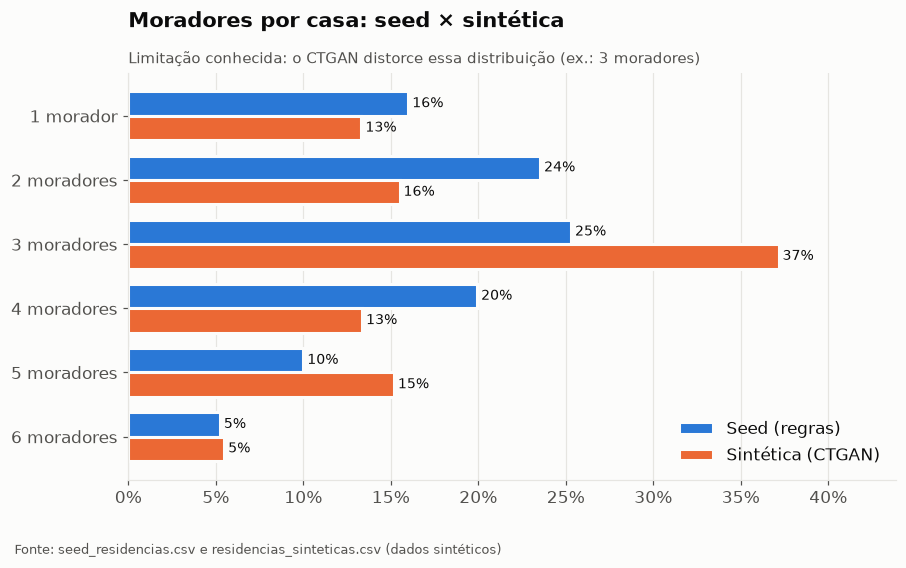

,seed,sintética
1 morador,16.0,13.3
2 moradores,23.5,15.5
3 moradores,25.3,37.2
4 moradores,19.9,13.4
5 moradores,10.0,15.2
6 moradores,5.2,5.5


In [7]:
mor = pd.DataFrame({"seed": seed["moradores"].value_counts(normalize=True),
                    "sintética": sint["moradores"].value_counts(normalize=True)}).sort_index().fillna(0)
mor.index = [f"{i} morador" + ("es" if i > 1 else "") for i in mor.index]

fig, ax = plt.subplots(figsize=(9, 4.8))
barras_lado_a_lado(ax, mor.index[::-1], mor["seed"][::-1], mor["sintética"][::-1], lambda v: f"{v:.0%}")
ax.xaxis.set_major_formatter(pct)
ax.set_xlim(0, mor.values.max() * 1.18)
ax.legend(loc="lower right")
ax.set_title("Moradores por casa: seed × sintética")
subtitulo(ax, "Limitação conhecida: o CTGAN distorce essa distribuição (ex.: 3 moradores)")
fonte(fig, "seed_residencias.csv e residencias_sinteticas.csv (dados sintéticos)")
salvar(fig, "06_moradores_seed_vs_sintetica.png")
(mor * 100).round(1)

## 4. Perfis do K-Means

O K-Means (k = 3) usa kWh por morador (em log, peso maior) e as frações do consumo que vêm do chuveiro,
do ar-condicionado e da geladeira. O nome do grupo vem do consumo médio por morador.
Os perfis são calculados com o mesmo `ml_pipeline.py` que a API usa.

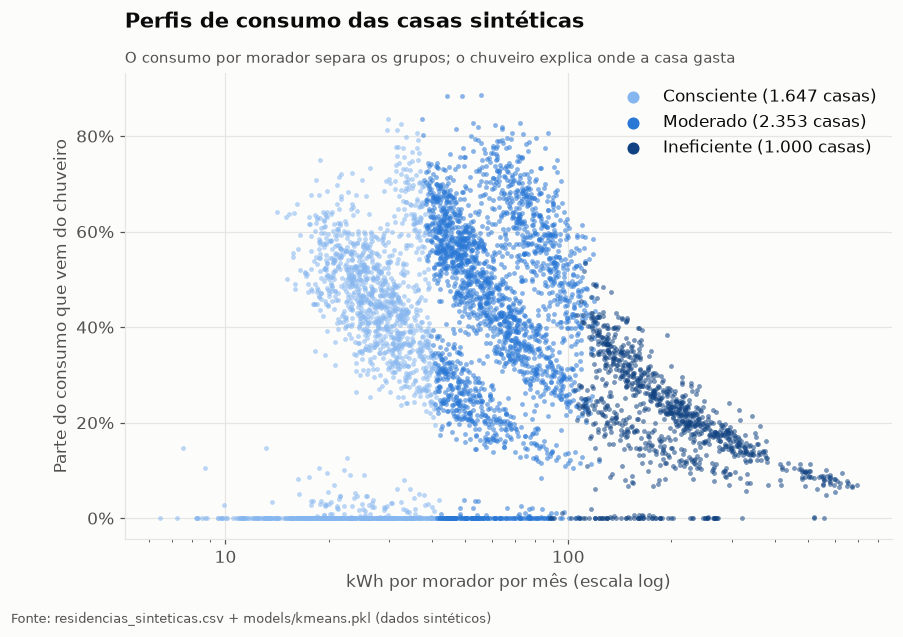

,kwh_por_morador,frac_chuveiro,frac_ar,frac_refrigerador,kwh_total
perfil,,,,,
Consciente,26.520,0.394,0.00,0.242,86.790
Moderado,60.620,0.465,0.00,0.162,190.500
Ineficiente,185.065,0.205,0.49,0.107,537.105


In [8]:
import ml_pipeline
modelo = ml_pipeline.carregar_modelo()
variaveis = modelo["variaveis"]
sint["perfil"] = [ml_pipeline.perfil_das_variaveis(l, modelo) for l in sint[variaveis].to_dict("records")]
ordem = ["Consciente", "Moderado", "Ineficiente"]

fig, ax = plt.subplots(figsize=(9, 5.5))
for p in ordem:
    d = sint[sint["perfil"] == p]
    ax.scatter(d["kwh_por_morador"], d["frac_chuveiro"], s=10, color=PERFIL_COR[p], alpha=0.55,
               linewidth=0, label=f"{p} ({len(d):,} casas)".replace(",", "."))
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: brl(v, 0)))
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("kWh por morador por mês (escala log)")
ax.set_ylabel("Parte do consumo que vem do chuveiro")
leg = ax.legend(loc="upper right", markerscale=2.5)
for h in leg.legend_handles:
    h.set_alpha(1)
ax.set_title("Perfis de consumo das casas sintéticas")
subtitulo(ax, "O consumo por morador separa os grupos; o chuveiro explica onde a casa gasta")
fonte(fig, "residencias_sinteticas.csv + models/kmeans.pkl (dados sintéticos)")
salvar(fig, "07_perfis_kmeans_dispersao.png")
sint.groupby("perfil")[variaveis + ["kwh_total"]].median().reindex(ordem).round(3)

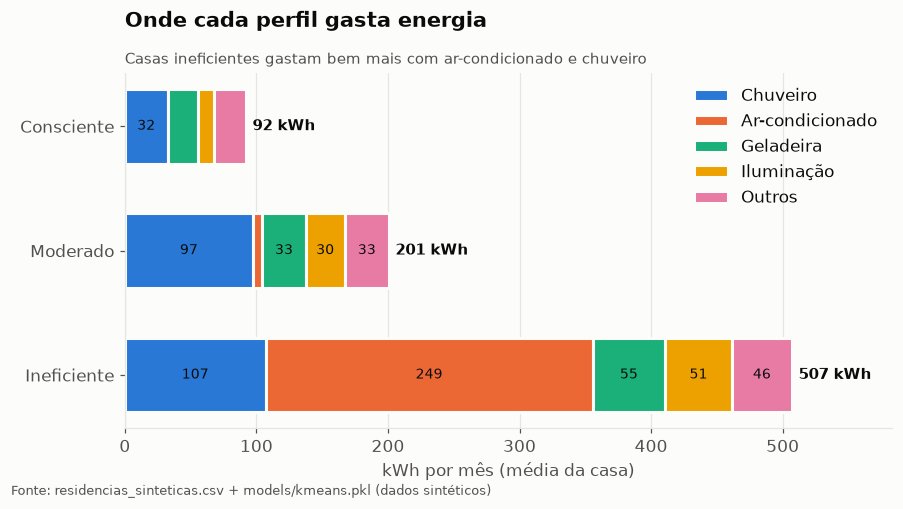

,Chuveiro,Ar-condicionado,Geladeira,Iluminação,Outros
perfil,,,,,
Consciente,32.5,0.2,22.7,12.7,24.0
Moderado,97.4,7.2,32.8,29.9,33.4
Ineficiente,107.0,248.5,55.3,50.6,45.8


In [9]:
grupos = {"Chuveiro": ["kwh_chuveiro"], "Ar-condicionado": ["kwh_ar_condicionado"],
          "Geladeira": ["kwh_refrigerador"], "Iluminação": ["kwh_iluminacao"],
          "Outros": ["kwh_televisor", "kwh_maquina_de_lavar", "kwh_microondas", "kwh_ventilador"]}
cores = [AZUL, LARANJA, AQUA, AMARELO, MAGENTA]
comp = pd.DataFrame({g: sint[cols].sum(axis=1) for g, cols in grupos.items()})
comp["perfil"] = sint["perfil"]
media = comp.groupby("perfil").mean().reindex(ordem)

fig, ax = plt.subplots(figsize=(9, 4.2))
esquerda = np.zeros(len(media))
y = np.arange(len(media))[::-1]
for (g, valores), cor in zip(media.items(), cores):
    ax.barh(y, valores, left=esquerda, color=cor, height=0.6, label=g, edgecolor=SUPERFICIE, linewidth=2)
    for yy, v, e in zip(y, valores, esquerda):
        if v >= 25:  # rotulo direto so nos segmentos com espaco
            ax.text(e + v / 2, yy, brl(v, 0), ha="center", va="center", fontsize=9, color=TEXTO)
    esquerda += valores.values
for yy, total in zip(y, esquerda):
    ax.text(total + 5, yy, f"{brl(total, 0)} kWh", va="center", fontsize=10, color=TEXTO, fontweight="bold")
ax.set_yticks(y, media.index)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, esquerda.max() * 1.15)
ax.set_xlabel("kWh por mês (média da casa)")
ax.legend(loc="upper right")
ax.set_title("Onde cada perfil gasta energia")
subtitulo(ax, "Casas ineficientes gastam bem mais com ar-condicionado e chuveiro")
fonte(fig, "residencias_sinteticas.csv + models/kmeans.pkl (dados sintéticos)")
salvar(fig, "08_perfis_composicao.png")
media.round(1)

## Limitações (para o documento de ética)

- O consumo do Inmetro é medido em **laboratório**, não no uso real; as horas de uso padrão são premissas do grupo.
- Tarifas **sem** ICMS, PIS/COFINS, bandeira e iluminação pública: a conta real é maior.
- As residências (seed e sintéticas) são **sintéticas**; os perfis servem para demonstração.
- O CTGAN preserva bem consumo e presença de aparelhos, mas **distorce a distribuição de moradores**.
- O K-Means coincide com o perfil usado na geração em ~73% da seed; os erros são entre perfis vizinhos.